In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import json
from pathlib import Path

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score
)

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

In [2]:
df = pd.read_csv(r"C:\Calibo\Phase-2\DL\synthetic_cardiometabolic_neural_network_dataset.csv")

df

,age_years,sex_female,bmi,systolic_bp_mmHg,diastolic_bp_mmHg,total_cholesterol_mg_dL,fasting_glucose_mg_dL,resting_heart_rate_bpm,smoking_current,family_history_cardiometabolic,physical_activity_level,sleep_hours,stress_level_1_to_5,elevated_cardiometabolic_risk
0,70,1,27.5,149,71,233,100,72,0,1,0,8.0,3,1
1,32,0,30.3,136,59,173,85,72,0,0,2,8.2,3,0
2,71,0,21.5,150,80,197,74,72,0,1,2,5.2,2,0
3,19,0,30.8,119,60,208,75,81,1,0,0,7.2,4,0
4,44,1,28.5,145,70,141,97,86,0,1,1,7.2,4,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7995,37,1,25.3,119,62,117,90,79,0,1,1,8.2,3,0
7996,71,1,25.5,140,83,232,101,67,1,1,2,5.5,4,0
7997,85,1,31.6,145,74,239,113,84,0,1,3,5.3,2,1
7998,43,0,28.0,136,69,177,86,82,0,0,2,6.6,3,0


## Data Understanding

In [3]:
df.shape

(8000, 14)

In [4]:
df.head()

,age_years,sex_female,bmi,systolic_bp_mmHg,diastolic_bp_mmHg,total_cholesterol_mg_dL,fasting_glucose_mg_dL,resting_heart_rate_bpm,smoking_current,family_history_cardiometabolic,physical_activity_level,sleep_hours,stress_level_1_to_5,elevated_cardiometabolic_risk
0,70,1,27.5,149,71,233,100,72,0,1,0,8.0,3,1
1,32,0,30.3,136,59,173,85,72,0,0,2,8.2,3,0
2,71,0,21.5,150,80,197,74,72,0,1,2,5.2,2,0
3,19,0,30.8,119,60,208,75,81,1,0,0,7.2,4,0
4,44,1,28.5,145,70,141,97,86,0,1,1,7.2,4,0


In [5]:
df.tail()

,age_years,sex_female,bmi,systolic_bp_mmHg,diastolic_bp_mmHg,total_cholesterol_mg_dL,fasting_glucose_mg_dL,resting_heart_rate_bpm,smoking_current,family_history_cardiometabolic,physical_activity_level,sleep_hours,stress_level_1_to_5,elevated_cardiometabolic_risk
7995,37,1,25.3,119,62,117,90,79,0,1,1,8.2,3,0
7996,71,1,25.5,140,83,232,101,67,1,1,2,5.5,4,0
7997,85,1,31.6,145,74,239,113,84,0,1,3,5.3,2,1
7998,43,0,28.0,136,69,177,86,82,0,0,2,6.6,3,0
7999,42,0,24.5,125,84,122,65,91,1,0,2,5.7,3,0


In [6]:
df.sample(5, random_state=42)

,age_years,sex_female,bmi,systolic_bp_mmHg,diastolic_bp_mmHg,total_cholesterol_mg_dL,fasting_glucose_mg_dL,resting_heart_rate_bpm,smoking_current,family_history_cardiometabolic,physical_activity_level,sleep_hours,stress_level_1_to_5,elevated_cardiometabolic_risk
2215,50,1,31.9,141,86,219,95,62,0,0,1,6.6,1,1
2582,42,1,28.1,117,88,154,87,60,0,0,1,6.0,2,0
1662,72,1,27.1,161,77,169,83,57,1,0,1,8.7,1,1
3027,24,1,23.6,130,78,144,68,55,0,0,3,10.2,1,0
4343,70,1,23.5,143,66,135,88,71,0,0,0,7.1,5,0


In [7]:
df.columns

Index(['age_years', 'sex_female', 'bmi', 'systolic_bp_mmHg',
       'diastolic_bp_mmHg', 'total_cholesterol_mg_dL', 'fasting_glucose_mg_dL',
       'resting_heart_rate_bpm', 'smoking_current',
       'family_history_cardiometabolic', 'physical_activity_level',
       'sleep_hours', 'stress_level_1_to_5', 'elevated_cardiometabolic_risk'],
      dtype='object')

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8000 entries, 0 to 7999
Data columns (total 14 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   age_years                       8000 non-null   int64  
 1   sex_female                      8000 non-null   int64  
 2   bmi                             8000 non-null   float64
 3   systolic_bp_mmHg                8000 non-null   int64  
 4   diastolic_bp_mmHg               8000 non-null   int64  
 5   total_cholesterol_mg_dL         8000 non-null   int64  
 6   fasting_glucose_mg_dL           8000 non-null   int64  
 7   resting_heart_rate_bpm          8000 non-null   int64  
 8   smoking_current                 8000 non-null   int64  
 9   family_history_cardiometabolic  8000 non-null   int64  
 10  physical_activity_level         8000 non-null   int64  
 11  sleep_hours                     8000 non-null   float64
 12  stress_level_1_to_5             80

In [9]:
df.dtypes

age_years                           int64
sex_female                          int64
bmi                               float64
systolic_bp_mmHg                    int64
diastolic_bp_mmHg                   int64
total_cholesterol_mg_dL             int64
fasting_glucose_mg_dL               int64
resting_heart_rate_bpm              int64
smoking_current                     int64
family_history_cardiometabolic      int64
physical_activity_level             int64
sleep_hours                       float64
stress_level_1_to_5                 int64
elevated_cardiometabolic_risk       int64
dtype: object

In [10]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
age_years,8000.0,51.316000,19.682272,18.0,34.0,51.0,68.0,85.0
sex_female,8000.0,0.507750,0.499971,0.0,0.0,1.0,1.0,1.0
bmi,8000.0,27.486237,4.575101,16.0,24.4,27.5,30.7,43.9
systolic_bp_mmHg,8000.0,134.217625,15.433131,88.0,124.0,134.0,145.0,188.0
diastolic_bp_mmHg,8000.0,72.484125,8.899039,50.0,67.0,73.0,79.0,107.0
total_cholesterol_mg_dL,8000.0,186.142750,30.614417,110.0,165.0,186.0,207.0,316.0
fasting_glucose_mg_dL,8000.0,89.551500,13.904568,60.0,80.0,89.0,99.0,143.0
resting_heart_rate_bpm,8000.0,72.343750,10.043577,45.0,66.0,72.0,79.0,112.0
smoking_current,8000.0,0.205750,0.404274,0.0,0.0,0.0,0.0,1.0
family_history_cardiometabolic,8000.0,0.291750,0.454596,0.0,0.0,0.0,1.0,1.0


In [11]:
df.nunique()

age_years                          68
sex_female                          2
bmi                               258
systolic_bp_mmHg                   95
diastolic_bp_mmHg                  56
total_cholesterol_mg_dL           175
fasting_glucose_mg_dL              77
resting_heart_rate_bpm             64
smoking_current                     2
family_history_cardiometabolic      2
physical_activity_level             4
sleep_hours                        71
stress_level_1_to_5                 5
elevated_cardiometabolic_risk       2
dtype: int64

In [12]:
df["sex_female"].value_counts()

sex_female
1    4062
0    3938
Name: count, dtype: int64

In [13]:
df["smoking_current"].value_counts()

smoking_current
0    6354
1    1646
Name: count, dtype: int64

In [14]:
df["physical_activity_level"].value_counts().sort_index()

physical_activity_level
0    1435
1    2520
2    2766
3    1279
Name: count, dtype: int64

In [15]:
df["stress_level_1_to_5"].value_counts().sort_index()

stress_level_1_to_5
1     980
2    1595
3    2530
4    1916
5     979
Name: count, dtype: int64

In [16]:
df.isnull().sum()

age_years                         0
sex_female                        0
bmi                               0
systolic_bp_mmHg                  0
diastolic_bp_mmHg                 0
total_cholesterol_mg_dL           0
fasting_glucose_mg_dL             0
resting_heart_rate_bpm            0
smoking_current                   0
family_history_cardiometabolic    0
physical_activity_level           0
sleep_hours                       0
stress_level_1_to_5               0
elevated_cardiometabolic_risk     0
dtype: int64

In [17]:
(df.isnull().sum() / len(df) * 100).round(2)

age_years                         0.0
sex_female                        0.0
bmi                               0.0
systolic_bp_mmHg                  0.0
diastolic_bp_mmHg                 0.0
total_cholesterol_mg_dL           0.0
fasting_glucose_mg_dL             0.0
resting_heart_rate_bpm            0.0
smoking_current                   0.0
family_history_cardiometabolic    0.0
physical_activity_level           0.0
sleep_hours                       0.0
stress_level_1_to_5               0.0
elevated_cardiometabolic_risk     0.0
dtype: float64

In [18]:
df.duplicated().sum()

np.int64(0)

In [19]:
df.select_dtypes(include=np.number).lt(0).sum()

age_years                         0
sex_female                        0
bmi                               0
systolic_bp_mmHg                  0
diastolic_bp_mmHg                 0
total_cholesterol_mg_dL           0
fasting_glucose_mg_dL             0
resting_heart_rate_bpm            0
smoking_current                   0
family_history_cardiometabolic    0
physical_activity_level           0
sleep_hours                       0
stress_level_1_to_5               0
elevated_cardiometabolic_risk     0
dtype: int64

In [20]:
binary_columns = [
    "sex_female",
    "smoking_current",
    "family_history_cardiometabolic"
]

df[binary_columns].apply(
    lambda col: sorted(col.dropna().unique())
)

,sex_female,smoking_current,family_history_cardiometabolic
0,0,0,0
1,1,1,1


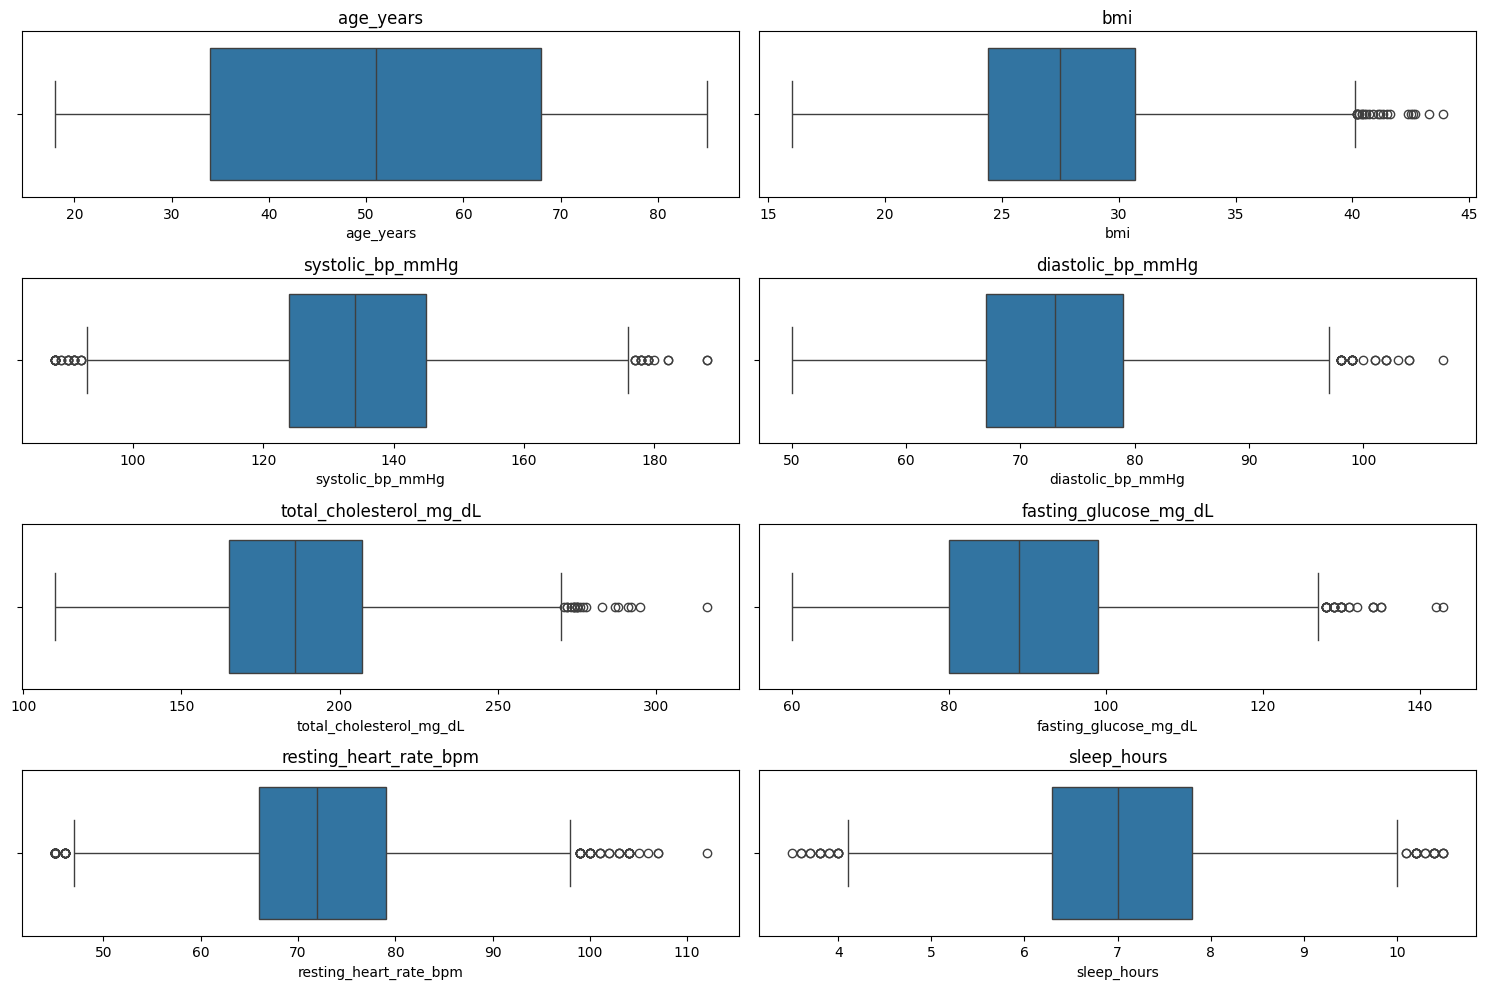

In [21]:
continuous_columns = [
    "age_years",
    "bmi",
    "systolic_bp_mmHg",
    "diastolic_bp_mmHg",
    "total_cholesterol_mg_dL",
    "fasting_glucose_mg_dL",
    "resting_heart_rate_bpm",
    "sleep_hours"
]

plt.figure(figsize=(15, 10))

for i, col in enumerate(continuous_columns, 1):
    plt.subplot(4, 2, i)
    sns.boxplot(x=df[col])
    plt.title(col)

plt.tight_layout()
plt.show()

In [22]:
outlier_summary = []

for col in continuous_columns:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1

    lower_limit = q1 - 1.5 * iqr
    upper_limit = q3 + 1.5 * iqr

    count = (
        (df[col] < lower_limit) |
        (df[col] > upper_limit)
    ).sum()

    outlier_summary.append({
        "Feature": col,
        "Lower Limit": lower_limit,
        "Upper Limit": upper_limit,
        "Outlier Count": count
    })

pd.DataFrame(outlier_summary)

,Feature,Lower Limit,Upper Limit,Outlier Count
0,age_years,-17.00,119.00,0
1,bmi,14.95,40.15,22
2,systolic_bp_mmHg,92.50,176.50,40
3,diastolic_bp_mmHg,49.00,97.00,29
4,total_cholesterol_mg_dL,102.00,270.00,20
5,fasting_glucose_mg_dL,51.50,127.50,29
6,resting_heart_rate_bpm,46.50,98.50,80
7,sleep_hours,4.05,10.05,34


## Exploratory Data Analysis (EDA)

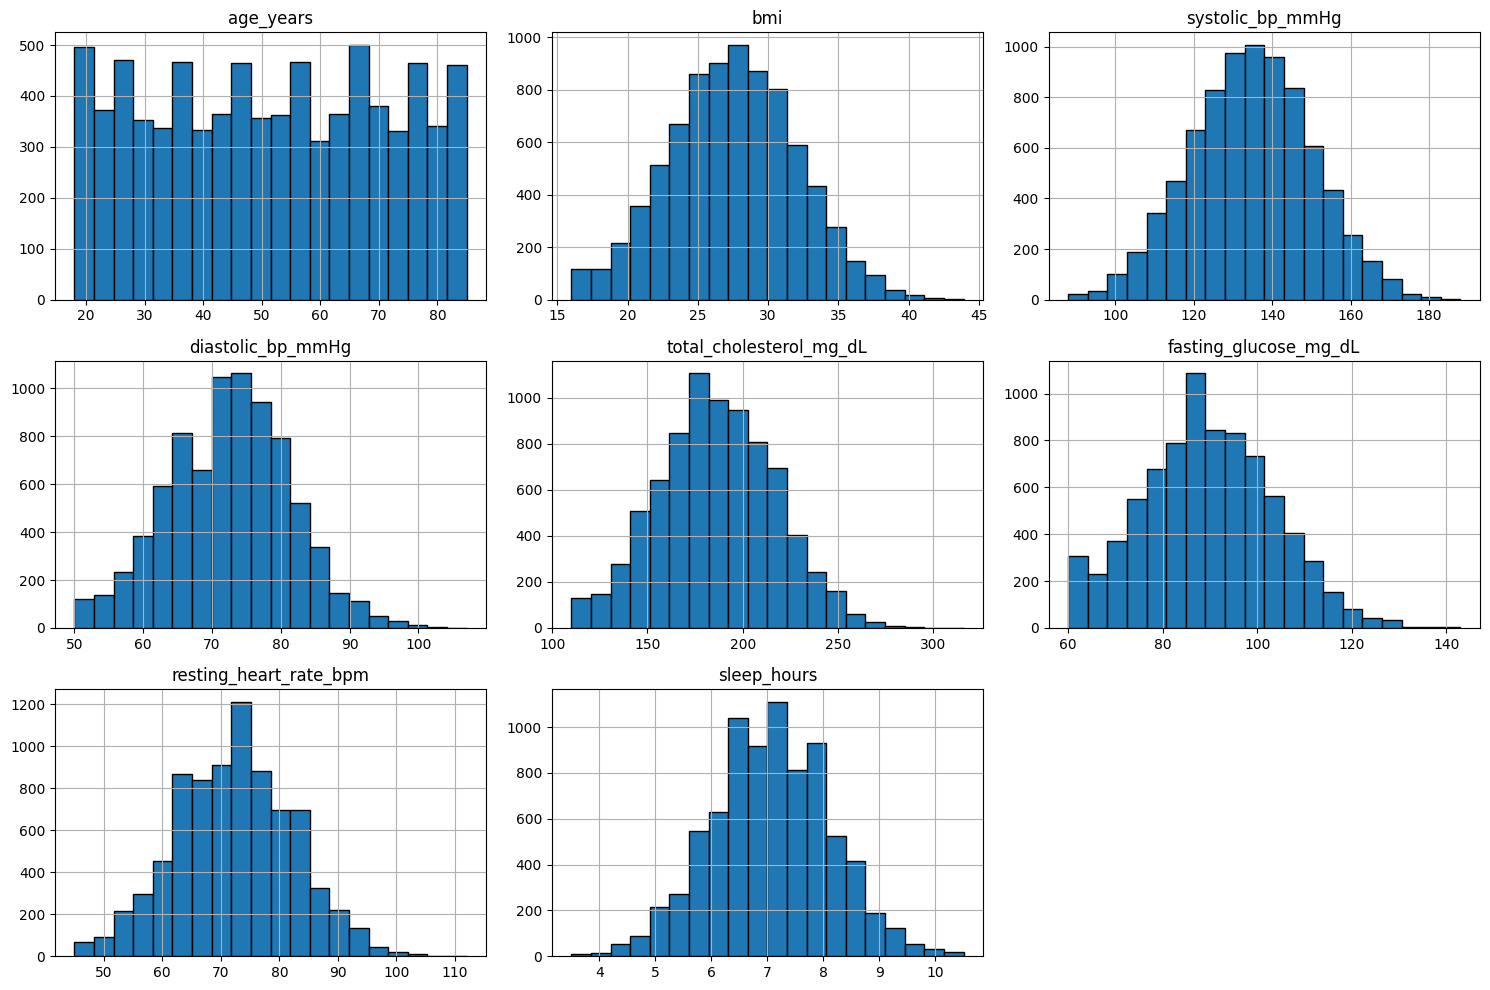

In [23]:
df[continuous_columns].hist(
    figsize=(15, 10),
    bins=20,
    edgecolor="black"
)

plt.tight_layout()
plt.show()

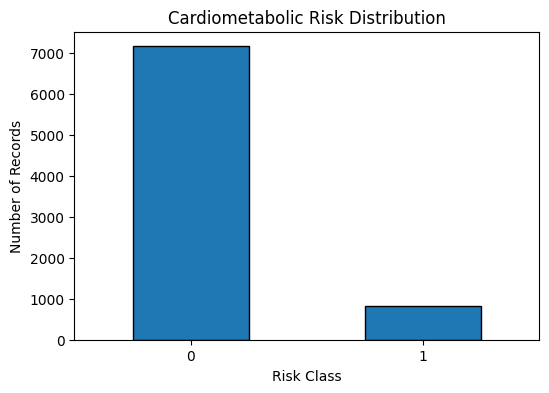

In [24]:
df["elevated_cardiometabolic_risk"].value_counts().sort_index().plot(
    kind="bar",
    figsize=(6, 4),
    edgecolor="black"
)

plt.title("Cardiometabolic Risk Distribution")
plt.xlabel("Risk Class")
plt.ylabel("Number of Records")
plt.xticks(rotation=0)
plt.show()

In [25]:
df["elevated_cardiometabolic_risk"].value_counts(normalize=True).mul(100).round(2)

elevated_cardiometabolic_risk
0    89.56
1    10.44
Name: proportion, dtype: float64

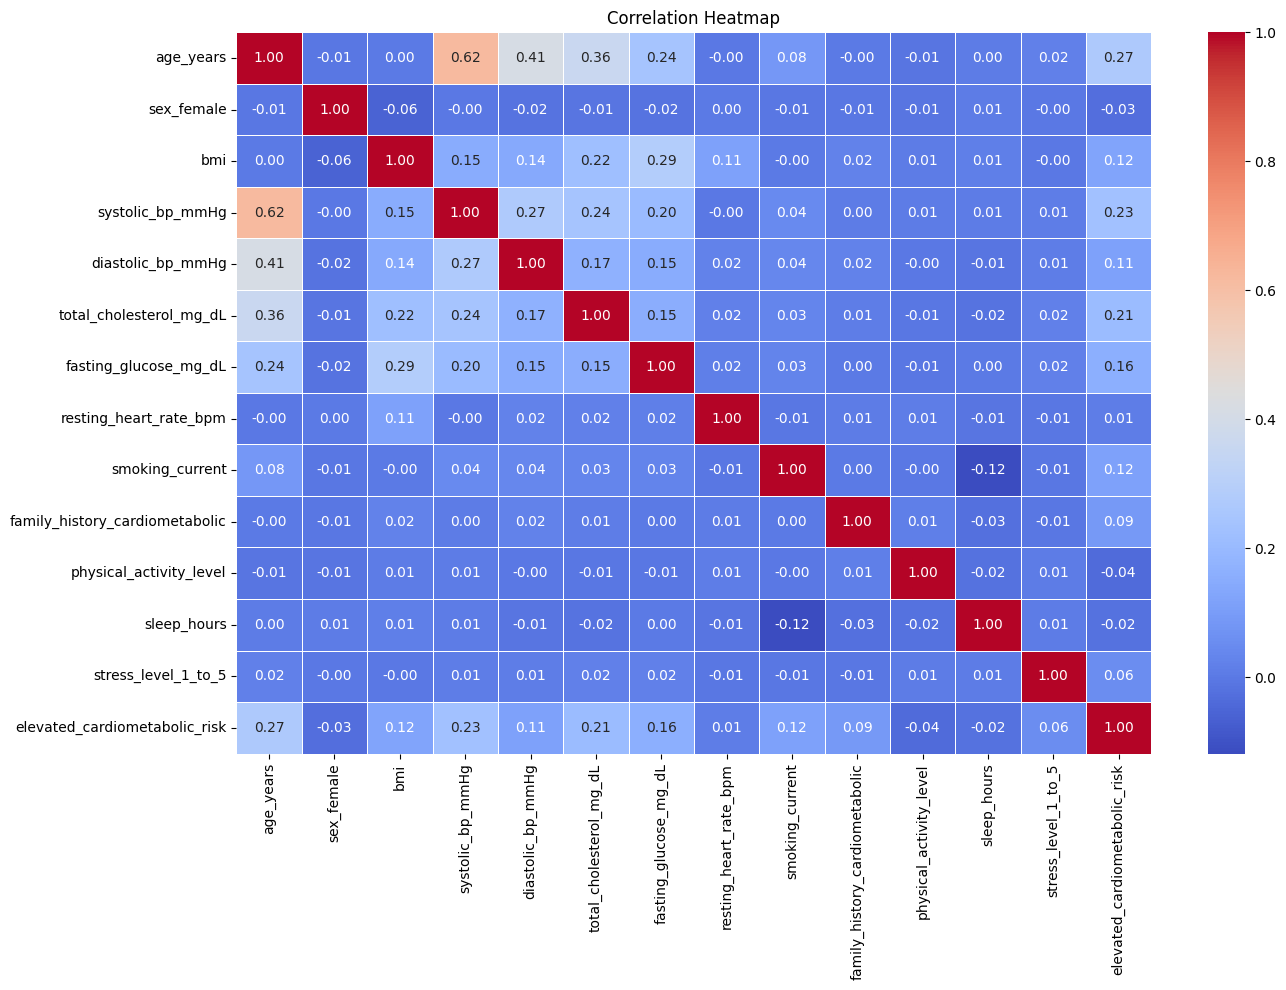

In [26]:
correlation_matrix = df.corr(numeric_only=True)

plt.figure(figsize=(14, 10))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    linewidths=0.5
)

plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

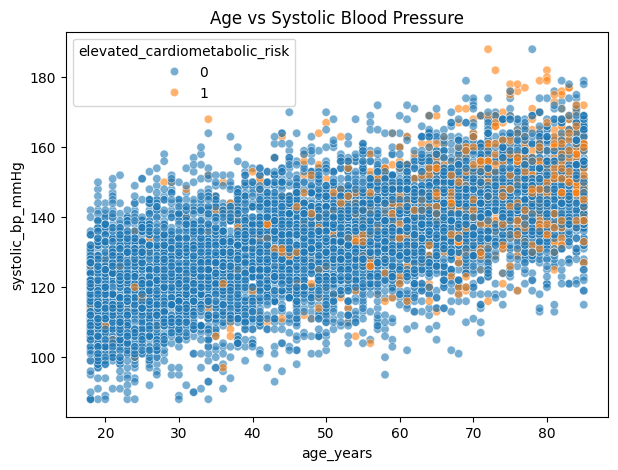

In [27]:
plt.figure(figsize=(7, 5))

sns.scatterplot(
    data=df,
    x="age_years",
    y="systolic_bp_mmHg",
    hue="elevated_cardiometabolic_risk",
    alpha=0.6
)

plt.title("Age vs Systolic Blood Pressure")
plt.show()

## Feature Engineering

In [28]:
df["pulse_pressure_mmHg"] = (
    df["systolic_bp_mmHg"] - df["diastolic_bp_mmHg"]
)

df[[
    "systolic_bp_mmHg",
    "diastolic_bp_mmHg",
    "pulse_pressure_mmHg"
]].head()

,systolic_bp_mmHg,diastolic_bp_mmHg,pulse_pressure_mmHg
0,149,71,78
1,136,59,77
2,150,80,70
3,119,60,59
4,145,70,75


## Data Splitting

In [29]:
target_column = "elevated_cardiometabolic_risk"

X = df.drop(columns=[target_column])
y = df[target_column]

In [30]:
X.shape, y.shape

((8000, 14), (8000,))

### Split into training, validation, and testing sets
We'll use 70% training, 15% validation, and 15% testing.

In [31]:
X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

In [32]:
pd.DataFrame({
    "Dataset": ["Training", "Validation", "Testing"],
    "Rows": [len(X_train), len(X_val), len(X_test)]
})

,Dataset,Rows
0,Training,5600
1,Validation,1200
2,Testing,1200


## Preprocessing

In [33]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_val_scaled = scaler.transform(X_val)

X_test_scaled = scaler.transform(X_test)

In [34]:
X_train_scaled.shape, X_val_scaled.shape, X_test_scaled.shape

((5600, 14), (1200, 14), (1200, 14))

In [35]:
tf.keras.utils.set_random_seed(42)

## ANN Architecture

In [36]:
model = keras.Sequential([
    keras.Input(shape=(X_train_scaled.shape[1],)),

    layers.Dense(
        64,
        activation="relu",
        kernel_regularizer=keras.regularizers.l2(0.001)
    ),

    layers.Dropout(0.3),

    layers.Dense(
        32,
        activation="relu",
        kernel_regularizer=keras.regularizers.l2(0.001)
    ),

    layers.Dropout(0.2),

    layers.Dense(1, activation="sigmoid")
])

In [37]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │           960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,073 (12.00 KB)

 Trainable params: 3,073 (12.00 KB)

 Non-trainable params: 0 (0.00 B)

## Compile the ANN

In [38]:
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        keras.metrics.AUC(name="auc")
    ]
)

## Callbacks

### Define the callbacks

In [39]:
early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=8,
    restore_best_weights=True,
    mode="min"
)

model_checkpoint = keras.callbacks.ModelCheckpoint(
    filepath="best_cardiometabolic_model.keras",
    monitor="val_loss",
    save_best_only=True,
    mode="min"
)

reduce_lr = keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=3,
    min_lr=0.00001,
    mode="min"
)

## Training

In [40]:
history = model.fit(
    X_train_scaled,
    y_train,
    validation_data=(X_val_scaled, y_val),
    epochs=100,
    batch_size=32,
    callbacks=[
        early_stopping,
        model_checkpoint,
        reduce_lr
    ],
    verbose=1
)

Epoch 1/100
175/175 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8780 - auc: 0.6716 - loss: 0.4048 - val_accuracy: 0.8958 - val_auc: 0.7929 - val_loss: 0.3404 - learning_rate: 0.0010
Epoch 2/100
175/175 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8954 - auc: 0.7731 - loss: 0.3429 - val_accuracy: 0.8958 - val_auc: 0.7986 - val_loss: 0.3286 - learning_rate: 0.0010
Epoch 3/100
175/175 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8961 - auc: 0.7918 - loss: 0.3268 - val_accuracy: 0.8983 - val_auc: 0.7995 - val_loss: 0.3214 - learning_rate: 0.0010
Epoch 4/100
175/175 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8982 - auc: 0.7970 - loss: 0.3182 - val_accuracy: 0.9017 - val_auc: 0.8005 - val_loss: 0.3146 - learning_rate: 0.0010
Epoch 5/100
175/175 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8982 - auc: 0.7987 - loss: 0.3121 - val_accuracy: 0.9008 - val_auc: 0.8028 - val_loss: 0.3089 - learning_rate: 0.0010
Epoch 6/100
175/175 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8970 - a

### Plot training and validation loss

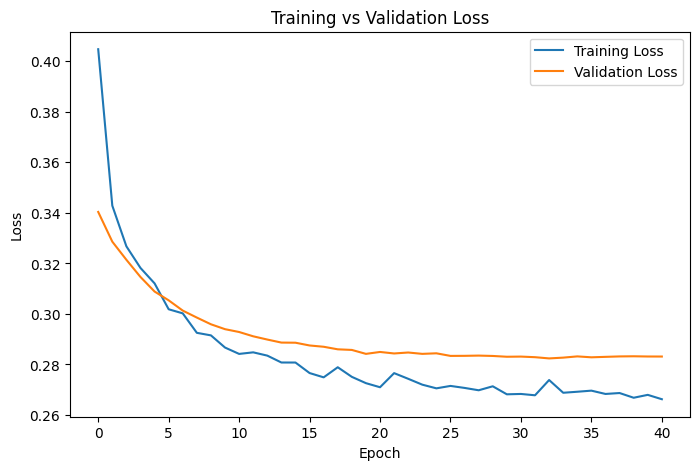

In [41]:
plt.figure(figsize=(8, 5))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training vs Validation Loss")
plt.legend()
plt.show()

### Plot training and validation accuracy

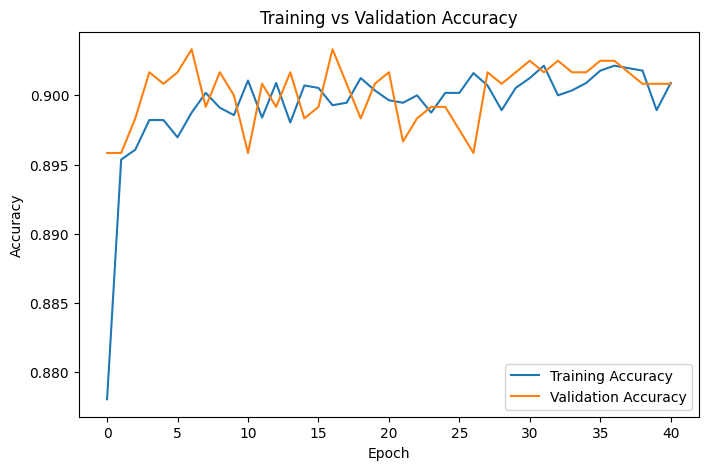

In [42]:
plt.figure(figsize=(8, 5))

plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training vs Validation Accuracy")
plt.legend()
plt.show()

## Evaluation

In [43]:
best_model = keras.models.load_model(
    "best_cardiometabolic_model.keras"
)

### Evaluate test performance

In [44]:
test_loss, test_accuracy, test_auc = best_model.evaluate(
    X_test_scaled,
    y_test,
    verbose=0
)

pd.DataFrame({
    "Metric": ["Test Loss", "Test Accuracy", "Test AUC"],
    "Value": [test_loss, test_accuracy, test_auc]
})

,Metric,Value
0,Test Loss,0.287755
1,Test Accuracy,0.900000
2,Test AUC,0.790913


### Generate test probabilities and classes

In [45]:
y_probability = best_model.predict(
    X_test_scaled,
    verbose=0
).ravel()

y_prediction = (y_probability >= 0.5).astype(int)

### Classification report

In [46]:
print(classification_report(
    y_test,
    y_prediction,
    zero_division=0
))

              precision    recall  f1-score   support

           0       0.91      0.99      0.95      1075
           1       0.61      0.11      0.19       125

    accuracy                           0.90      1200
   macro avg       0.76      0.55      0.57      1200
weighted avg       0.87      0.90      0.87      1200



### Confusion matrix

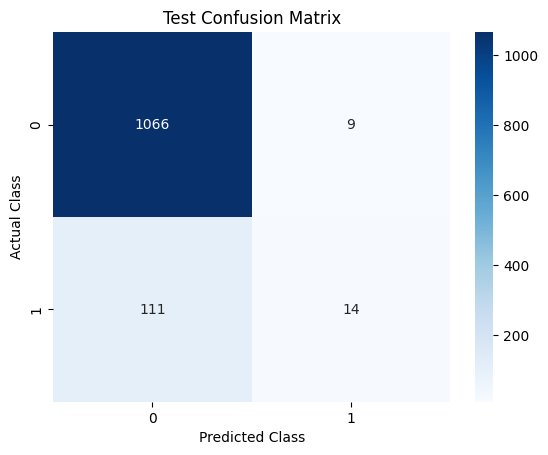

In [47]:
cm = confusion_matrix(y_test, y_prediction)

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title("Test Confusion Matrix")
plt.show()

### Calculate evaluation metrics

In [48]:
evaluation_results = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1 Score",
        "ROC-AUC"
    ],
    "Value": [
        accuracy_score(y_test, y_prediction),
        precision_score(y_test, y_prediction, zero_division=0),
        recall_score(y_test, y_prediction, zero_division=0),
        f1_score(y_test, y_prediction, zero_division=0),
        roc_auc_score(y_test, y_probability)
    ]
})

evaluation_results

,Metric,Value
0,Accuracy,0.900000
1,Precision,0.608696
2,Recall,0.112000
3,F1 Score,0.189189
4,ROC-AUC,0.791286


## Model Saving

In [49]:
best_model.save("final_cardiometabolic_model.keras")

## Preprocessing Saving

In [50]:
joblib.dump(
    scaler,
    "cardiometabolic_scaler.pkl"
)

['cardiometabolic_scaler.pkl']

In [51]:
feature_columns = X.columns.tolist()

with open("cardiometabolic_features.json", "w") as file:
    json.dump(feature_columns, file)

## Prediction

In [52]:
loaded_model = keras.models.load_model(
    "final_cardiometabolic_model.keras"
)

loaded_scaler = joblib.load(
    "cardiometabolic_scaler.pkl"
)

with open("cardiometabolic_features.json", "r") as file:
    saved_features = json.load(file)

### Predict using unseen test records

In [53]:
test_records = X_test[saved_features].copy()

test_records_scaled = loaded_scaler.transform(test_records)

prediction_probabilities = loaded_model.predict(
    test_records_scaled,
    verbose=0
).ravel()

predicted_classes = (
    prediction_probabilities >= 0.5
).astype(int)

prediction_df = pd.DataFrame({
    "Predicted_Probability": prediction_probabilities,
    "Predicted_Class": predicted_classes
}, index=test_records.index)

prediction_df.head(10)

,Predicted_Probability,Predicted_Class
3675,0.196066,0
3431,0.170372,0
220,0.001747,0
5649,0.033942,0
6893,0.060638,0
7649,0.222899,0
5275,0.021151,0
1817,0.026990,0
6542,0.007376,0
5466,0.119095,0


### Compare actual and predicted results

In [54]:
final_results = pd.DataFrame({
    "Actual_Class": y_test,
    "Predicted_Class": predicted_classes,
    "Predicted_Probability": prediction_probabilities
}, index=X_test.index)

final_results.head(20)

,Actual_Class,Predicted_Class,Predicted_Probability
3675,0,0,0.196066
3431,1,0,0.170372
220,0,0,0.001747
5649,0,0,0.033942
6893,0,0,0.060638
7649,0,0,0.222899
5275,0,0,0.021151
1817,0,0,0.026990
6542,1,0,0.007376
5466,1,0,0.119095
